Iris Dataset:
   Sample_ID  Sepal_Length  Sepal_Width  Petal_Length  Petal_Width
0          1           5.1          3.5           1.4          0.2
1          2           4.9          3.0           1.4          0.2
2          3           4.7          3.2           1.3          0.2
3          4           4.6          3.1           1.5          0.2
4          5           5.0          3.6           1.4          0.2
5          6           5.4          3.9           1.7          0.4
6          7           4.6          3.4           1.4          0.3
7          8           5.0          3.4           1.5          0.2
8          9           4.4          2.9           1.4          0.2
9         10           4.9          3.1           1.5          0.1

Dataset Shape: (150, 5)

Cluster Assignments:
   Sample_ID  Sepal_Length  Sepal_Width  Petal_Length  Petal_Width  \
0          1           5.1          3.5           1.4          0.2   
1          2           4.9          3.0           1.4         

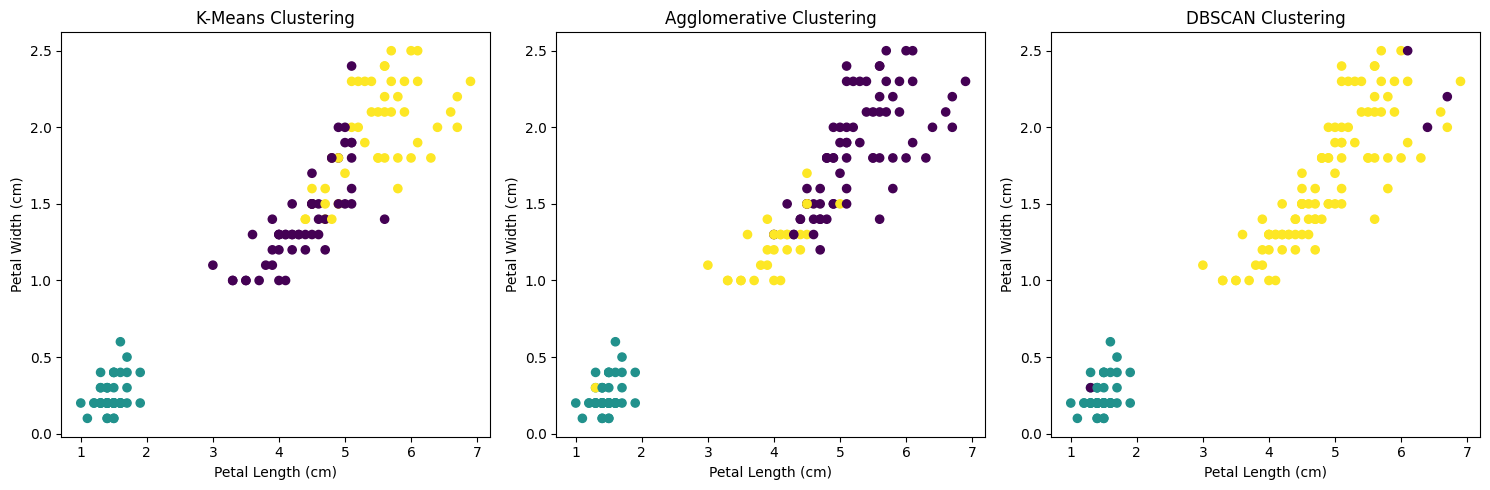


Cluster Counts:
K-Means
0    53
1    50
2    47
Name: count, dtype: int64
Agglomerative
0    71
1    49
2    30
Name: count, dtype: int64
DBSCAN
-1     4
 0    49
 1    97
Name: count, dtype: int64

Dataset and evaluation results saved successfully.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN
)
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

# Load the Iris dataset
iris = load_iris(as_frame=True)

df = iris.data.copy()

df.columns = [
    "Sepal_Length",
    "Sepal_Width",
    "Petal_Length",
    "Petal_Width"
]

df.insert(0, "Sample_ID", range(1, len(df) + 1))

print("Iris Dataset:")
print(df.head(10))

print("\nDataset Shape:", df.shape)

# Save the dataset
df.to_csv("Iris_Clustering_Dataset.csv", index=False)

# Select features for clustering
features = df[
    [
        "Sepal_Length",
        "Sepal_Width",
        "Petal_Length",
        "Petal_Width"
    ]
]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# K-Means Clustering
df["KMeans_Cluster"] = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
).fit_predict(X_scaled)

# Agglomerative Clustering
df["Agglomerative_Cluster"] = AgglomerativeClustering(
    n_clusters=3
).fit_predict(X_scaled)

# DBSCAN Clustering
df["DBSCAN_Cluster"] = DBSCAN(
    eps=0.8,
    min_samples=5
).fit_predict(X_scaled)

print("\nCluster Assignments:")
print(df.head(10))


# Evaluation function
def evaluate_model(X, labels):

    # Exclude noise points labelled -1
    valid = labels != -1

    X_valid = X[valid]
    labels_valid = labels[valid]

    n_clusters = len(set(labels_valid))

    if n_clusters < 2 or n_clusters >= len(labels_valid):
        return np.nan, np.nan

    silhouette = silhouette_score(
        X_valid,
        labels_valid
    )

    db_index = davies_bouldin_score(
        X_valid,
        labels_valid
    )

    return silhouette, db_index


# Compare the algorithms
algorithms = {
    "K-Means": df["KMeans_Cluster"].to_numpy(),
    "Agglomerative": df["Agglomerative_Cluster"].to_numpy(),
    "DBSCAN": df["DBSCAN_Cluster"].to_numpy()
}

results = []

for name, labels in algorithms.items():

    silhouette, db_index = evaluate_model(
        X_scaled,
        labels
    )

    results.append({
        "Algorithm": name,
        "Clusters": len(set(labels) - {-1}),
        "Noise Points": int(np.sum(labels == -1)),
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index
    })

results_df = pd.DataFrame(results)

print("\nClustering Performance:")
print(results_df.round(3).to_string(index=False))

# Save evaluation results
results_df.to_csv(
    "Iris_Clustering_Metrics.csv",
    index=False
)


# Visualize the clusters
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

cluster_columns = [
    "KMeans_Cluster",
    "Agglomerative_Cluster",
    "DBSCAN_Cluster"
]

titles = [
    "K-Means Clustering",
    "Agglomerative Clustering",
    "DBSCAN Clustering"
]

for ax, column, title in zip(
    axes,
    cluster_columns,
    titles
):

    ax.scatter(
        df["Petal_Length"],
        df["Petal_Width"],
        c=df[column],
        cmap="viridis",
        s=35
    )

    ax.set_title(title)
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")

plt.tight_layout()

plt.savefig(
    "Iris_Clustering_Comparison.png",
    dpi=150
)

plt.show()


# Display cluster counts
print("\nCluster Counts:")

for name, labels in algorithms.items():

    print(name)

    print(
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

print("\nDataset and evaluation results saved successfully.")